# Proyecto final – Preparación del modelo y prueba de la API con Cloudflare Tunnel
**Proyecto:** Asistente de reclutamiento del restaurante El Sauce · **Alumna:** Juana Paola Puente Huerta

Este cuaderno tiene cuatro partes:
1. **Convertir el modelo de visión a TensorFlow Lite.** El modelo Keras pesa mucho para la nube; la versión Lite
   da las mismas predicciones y carga mucho más rápido en Streamlit Community Cloud.
2. **Probar la API REST (Flask) desde internet con Cloudflare Tunnel**, como evidencia de que la API funciona
   como servicio independiente de la interfaz.
3. **Métricas del chatbot:** conversaciones automáticas de punta a punta a través de la API.
4. **Prueba de carga:** tiempo de respuesta con varios usuarios simultáneos (análisis de escalabilidad).

## Parte 1. Convertir el modelo a TensorFlow Lite

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, numpy as np, tensorflow as tf, keras
from PIL import Image, ImageOps

RUTA = '/content/drive/MyDrive/ChatbotRH'
RUTA_MODELO = os.path.join(RUTA, 'modelo')

modelo = keras.models.load_model(os.path.join(RUTA_MODELO, 'modelo_documentos.keras'))
CLASES = json.load(open(os.path.join(RUTA_MODELO, 'clases.json')))
print("Modelo Keras cargado. Clases:", CLASES)

Mounted at /content/drive
Modelo Keras cargado. Clases: ['comprobante', 'ine', 'licencia', 'otro']


In [2]:
# Modelo para producción: el mismo modelo entrenado, sin las capas de aumento de datos
# (esas capas solo sirven para entrenar y TensorFlow Lite no puede convertirlas)
base = next(c for c in modelo.layers if c.name.startswith('efficientnet'))
pooling = next(c for c in modelo.layers if isinstance(c, keras.layers.GlobalAveragePooling2D))
salida = modelo.layers[-1]                       # capa Dense con las 4 clases
entrada = keras.Input(shape=(224, 224, 3))
modelo_inferencia = keras.Model(entrada, salida(pooling(base(entrada, training=False))))

modelo_inferencia.export('/content/modelo_saved')
convertidor = tf.lite.TFLiteConverter.from_saved_model('/content/modelo_saved')
modelo_tflite = convertidor.convert()

ruta_tflite = os.path.join(RUTA_MODELO, 'modelo_documentos.tflite')
with open(ruta_tflite, 'wb') as f:
    f.write(modelo_tflite)
print(f"Keras: {os.path.getsize(os.path.join(RUTA_MODELO, 'modelo_documentos.keras')) / 1e6:.1f} MB")
print(f"TFLite: {os.path.getsize(ruta_tflite) / 1e6:.1f} MB  ->  guardado en {ruta_tflite}")

Saved artifact at '/content/modelo_saved'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_524')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  133886853124880: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  133886853124688: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  133886974934096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886974934288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886974932752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886974934672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886974934480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886969234064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886969234448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133886969234256: TensorSpec(shape=(), dtype=tf.resource, 

### Verificación: el modelo Lite debe dar las mismas predicciones que el original

In [3]:
interprete = tf.lite.Interpreter(model_path=ruta_tflite)
interprete.allocate_tensors()
ent = interprete.get_input_details()[0]['index']
sal = interprete.get_output_details()[0]['index']

def cargar(ruta):
    img = ImageOps.exif_transpose(Image.open(ruta)).convert('RGB')
    return np.asarray(ImageOps.pad(img, (224, 224), color=(0, 0, 0)), dtype=np.float32)[None, ...]

RUTA_PRUEBAS = os.path.join(RUTA, 'pruebas')
for archivo in sorted(os.listdir(RUTA_PRUEBAS)):
    if archivo.lower().endswith('.pdf'):
        continue
    x = cargar(os.path.join(RUTA_PRUEBAS, archivo))
    p_keras = modelo.predict(x, verbose=0)[0]
    interprete.set_tensor(ent, x); interprete.invoke()
    p_lite = interprete.get_tensor(sal)[0]
    print(f"{archivo:<28} Keras: {CLASES[p_keras.argmax()]:<12} {p_keras.max():.3f} | "
          f"TFLite: {CLASES[p_lite.argmax()]:<12} {p_lite.max():.3f} | diferencia máx: {np.abs(p_keras - p_lite).max():.5f}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


comprobante_prueba-jpg.webp  Keras: comprobante  0.384 | TFLite: comprobante  0.384 | diferencia máx: 0.00001
ine_prueba.jpeg              Keras: ine          0.610 | TFLite: ine          0.610 | diferencia máx: 0.00000
licencia_prueba.jpeg         Keras: licencia     0.751 | TFLite: licencia     0.751 | diferencia máx: 0.00000
otro_prueba.jpeg             Keras: licencia     0.682 | TFLite: licencia     0.682 | diferencia máx: 0.00000


Si las clases coinciden y la diferencia es muy pequeña (menor a 0.01), la conversión es correcta.

**Siguiente paso:** descarga `modelo_documentos.tflite` y `clases.json` de la carpeta `ChatbotRH/modelo`
de tu Drive y súbelos a la carpeta `proyecto_final/modelo/` de tu repositorio en GitHub.

## Parte 2. Probar la API REST con Cloudflare Tunnel
Se descarga el código desde GitHub, se ejecuta la API Flask en este cuaderno y Cloudflare Tunnel
le asigna una **URL pública temporal** para poder llamarla desde cualquier lugar.

> La URL de Cloudflare deja de funcionar cuando se cierra este cuaderno. La URL permanente de la aplicación
> es la de Streamlit Community Cloud; esta prueba sirve para demostrar la API como servicio independiente.

In [33]:
%cd /content
!rm -rf Chatbot-RH
!git clone -q https://github.com/paolaphuerta/Chatbot-RH.git
%cd /content/Chatbot-RH/proyecto_final
!pip install -q flask nltk pillow-heif pymupdf ai-edge-litert
!ls modelo

/content
/content/Chatbot-RH/proyecto_final
clases.json  modelo_documentos.tflite


In [34]:
# Inicia la API Flask en segundo plano (puerto 5000)
import subprocess, time, requests
api = subprocess.Popen(['python', '-m', 'api.servidor'], stdout=open('/content/api.log', 'w'), stderr=subprocess.STDOUT)
for _ in range(60):
    try:
        if requests.get('http://localhost:5000/api/salud', timeout=2).ok:
            break
    except requests.RequestException:
        time.sleep(1)
print(requests.get('http://localhost:5000/api/salud').json())

{'ok': True, 'estado': 'en línea', 'segundos_activo': 2, 'modelo_texto': {'frases_entrenamiento': 320, 'intenciones': 15}, 'modelo_vision': {'motor': 'tflite', 'clases': ['comprobante', 'ine', 'licencia', 'otro']}, 'puestos': 7}


In [35]:
# Descarga cloudflared y abre un túnel público hacia la API
!wget -q -O /content/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x /content/cloudflared
import re
tunel = subprocess.Popen(['/content/cloudflared', 'tunnel', '--url', 'http://localhost:5000', '--no-autoupdate'],
                         stdout=open('/content/tunel.log', 'w'), stderr=subprocess.STDOUT)
URL = None
for _ in range(60):
    time.sleep(1)
    m = re.search(r'https://[a-z0-9-]+\.trycloudflare\.com', open('/content/tunel.log').read())
    if m:
        URL = m.group(0); break
print("URL pública de la API:", URL)

URL pública de la API: https://advertise-minute-pam-players.trycloudflare.com


In [36]:
# Espera hasta que la URL pública responda (máximo 2 minutos)
for intento in range(40):
    try:
        r = requests.get(URL + '/api/salud', timeout=10)
        if r.ok:
            print(f"✅ Túnel listo después de {intento * 3} segundos:", URL + '/api/salud')
            break
    except requests.RequestException:
        pass
    time.sleep(3)
else:
    print("❌ El túnel no respondió. Vuelve a ejecutar la celda de Cloudflare.")

✅ Túnel listo después de 3 segundos: https://advertise-minute-pam-players.trycloudflare.com/api/salud


### Pruebas de los servicios de la API a través de la URL pública

In [23]:
import json
def ver(r):
    print(r.status_code, json.dumps(r.json(), ensure_ascii=False, indent=2)[:1200], '\n')

time.sleep(5)   # el túnel tarda unos segundos en estar listo
print("GET /api/salud"); ver(requests.get(URL + '/api/salud', timeout=30))
print("POST /api/intencion"); ver(requests.post(URL + '/api/intencion', json={'mensaje': 'cuanto pagan d mesra'}, timeout=30))

GET /api/salud
200 {
  "estado": "en línea",
  "modelo_texto": {
    "frases_entrenamiento": 320,
    "intenciones": 15
  },
  "modelo_vision": {
    "clases": [
      "comprobante",
      "ine",
      "licencia",
      "otro"
    ],
    "motor": "tflite"
  },
  "ok": true,
  "puestos": 7,
  "segundos_activo": 174
} 

POST /api/intencion
200 {
  "confianza": 0.797,
  "intencion": "sueldo",
  "ok": true,
  "texto_preprocesado": "cuant pag d mesr"
} 



In [8]:
# Clasificación de un documento (usa una imagen de tu carpeta de pruebas)
ruta_img = [os.path.join(RUTA_PRUEBAS, f) for f in sorted(os.listdir(RUTA_PRUEBAS)) if f.startswith('ine')][0]
with open(ruta_img, 'rb') as f:
    print("POST /api/documento"); ver(requests.post(URL + '/api/documento', files={'archivo': (os.path.basename(ruta_img), f)}, timeout=60))

POST /api/documento
200 {
  "clase": "ine",
  "confianza": 0.61,
  "ok": true,
  "probabilidades": {
    "comprobante": 0.005,
    "ine": 0.61,
    "licencia": 0.339,
    "otro": 0.046
  }
} 



In [9]:
# Conversación con el agente a través de la API
sesion = 'prueba-colab'
for m in ['hola', 'me interesa ser runner', '22', 'si']:
    r = requests.post(URL + '/api/agente/mensaje', json={'sesion': sesion, 'mensaje': m}, timeout=30).json()
    print(f"Usuario: {m}\n  [{r['capa']} · {r['accion']} · plan: {r['plan'][:3]}]\nBot: {r['respuesta']}\n")

Usuario: hola
  [reactiva · responder_faq · plan: []]
Bot: ¡Hola! Soy el asistente virtual de reclutamiento de El Sauce. 😊 Soy un programa automático; las decisiones finales las toma recursos humanos.
Puedo ayudarte con: vacantes, funciones, sueldos, horarios, experiencia, prestaciones, propinas, documentos y entrevistas.
Si quieres postularte, escribe "me interesa".

Usuario: me interesa ser runner
  [deliberativa · iniciar_postulacion · plan: ['edad', 'horario', 'doc_ine']]
Bot: ¡Qué gusto! Te haré unas preguntas rápidas para el puesto de Runner (si te interesa otro, escribe "cancelar").
¿Cuántos años tienes? (escribe un número)

Usuario: 22
  [deliberativa · registrar_dato · plan: ['horario', 'doc_ine', 'doc_comprobante']]
Bot: Los horarios de Runner son: 6:00 a 16:00 / 7:00 a 17:00. ¿Puedes cubrir alguno? (sí / no)

Usuario: si
  [deliberativa · registrar_dato · plan: ['doc_ine', 'doc_comprobante', 'dia']]
Bot: ✅ **¡Tu perfil es compatible con el puesto de Runner!**
Antes de agenda

In [10]:
# Manejo de errores: la API responde con un mensaje claro en lugar de fallar
print("Sin mensaje:"); ver(requests.post(URL + '/api/agente/mensaje', json={'sesion': 'x'}, timeout=30))
print("Archivo no permitido:"); ver(requests.post(URL + '/api/documento', files={'archivo': ('notas.txt', b'hola')}, timeout=30))
print("Métricas de operación:"); ver(requests.get(URL + '/api/metricas', timeout=30))

Sin mensaje:
400 {
  "error": "Falta el campo: mensaje.",
  "ok": false
} 

Archivo no permitido:
422 {
  "error": "Formato no permitido. Envía una foto (JPG, PNG, HEIC, WEBP) o un PDF.",
  "ok": false
} 

Métricas de operación:
200 {
  "acciones": {
    "iniciar_postulacion": 1,
    "registrar_dato": 2,
    "responder_faq": 1
  },
  "documentos": {},
  "errores": 2,
  "intenciones": {
    "no_entendido": 2,
    "postularse": 1,
    "saludo": 1
  },
  "latencia_p95_ms": null,
  "latencia_promedio_ms": 98.8,
  "ok": true,
  "peticiones": 8,
  "por_ruta": {
    "/api/agente/mensaje": {
      "errores": 1,
      "latencia_promedio_ms": 20.9,
      "peticiones": 5
    },
    "/api/documento": {
      "errores": 1,
      "latencia_promedio_ms": 318.1,
      "peticiones": 2
    },
    "/api/intencion": {
      "errores": 0,
      "latencia_promedio_ms": 50.2,
      "peticiones": 1
    }
  },
  "satisfaccion": {
    "calificaciones": 0,
    "no_utiles_por_accion": {},
    "tasa_util": null
  

## Parte 3. Métricas del chatbot
Se ejecutan automáticamente **45 frases nuevas** (no usadas para entrenar) y **15 conversaciones completas**
(postulaciones exitosas, rechazos por requisito, documento equivocado, imagen que no es documento, duda a mitad
del proceso, faltas de ortografía y cancelación) a través de la API pública. Se usan las fotos de tu carpeta `pruebas`.

In [11]:
import sys, matplotlib.pyplot as plt
sys.path.insert(0, '/content/Chatbot-RH/proyecto_final')
from pruebas.evaluacion import Cliente, metricas_chatbot, prueba_carga

def buscar(prefijo, preferir_pdf=False):
    archivos = sorted(f for f in os.listdir(RUTA_PRUEBAS) if f.lower().startswith(prefijo))
    if preferir_pdf:
        archivos.sort(key=lambda f: not f.lower().endswith('.pdf'))
    return os.path.join(RUTA_PRUEBAS, archivos[0])

DOCUMENTOS = {'ine': buscar('ine'), 'licencia': buscar('licencia'),
              'comprobante': buscar('comprobante', preferir_pdf=True), 'otro': buscar('otro')}
print(DOCUMENTOS)

resultados = metricas_chatbot(Cliente(URL), DOCUMENTOS)
resultados['resumen'].to_frame()

{'ine': '/content/drive/MyDrive/ChatbotRH/pruebas/ine_prueba.jpeg', 'licencia': '/content/drive/MyDrive/ChatbotRH/pruebas/licencia_prueba.jpeg', 'comprobante': '/content/drive/MyDrive/ChatbotRH/pruebas/comprobante_prueba-jpg.webp', 'otro': '/content/drive/MyDrive/ChatbotRH/pruebas/otro_prueba.jpeg'}


,Valor
Precisión de intención en conversación,95.6% (43/45)
Confianza promedio del NLP,0.69
Tasa de éxito de tareas,100.0% (15/15)
Turnos promedio por postulación agendada,11.5
Documentos aceptados al primer intento,52.4%
Documentos escalados a RH,10
Peticiones con error (5xx),0
Tiempo de respuesta promedio (ms),81


In [12]:
# Éxito por escenario de punta a punta
resultados['tareas']

,escenario,esperado,resultado,exito,turnos
0,Mesero completo,agendada,agendada,True,12
1,Ayudante de cocina completo,agendada,agendada,True,11
2,Cocinero completo,agendada,agendada,True,11
3,Lavaloza sin experiencia,agendada,agendada,True,11
4,Repartidor con licencia,agendada,agendada,True,13
5,Runner con duda a mitad,agendada,agendada,True,11
6,Vendedor con documento equivocado,agendada,agendada,True,11
7,Faltas de ortografía,agendada,agendada,True,12
8,Desde tarjeta de puesto,agendada,agendada,True,12
9,Imagen que no es documento,agendada,agendada,True,11


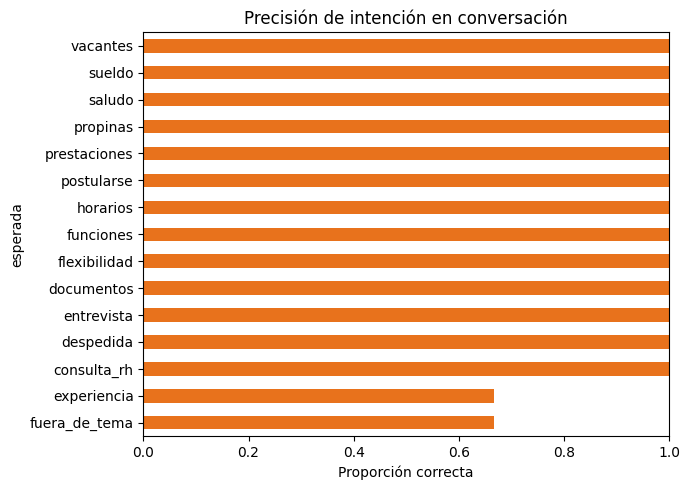

,frase,esperada,detectada,confianza
20,es mi primer empleo,experiencia,no_entendido,0.28
42,quiero ordenar comida,fuera_de_tema,postularse,0.43


In [13]:
# Precisión de la intención por tipo de pregunta y frases que fallaron
porc = resultados['intenciones'].groupby('esperada')['correcta'].mean().sort_values()
porc.plot(kind='barh', figsize=(7, 5), color='#E8721C', xlim=(0, 1), title='Precisión de intención en conversación')
plt.xlabel('Proporción correcta'); plt.tight_layout(); plt.show()
fallas = resultados['intenciones'][~resultados['intenciones']['correcta']]
fallas[['frase', 'esperada', 'detectada', 'confianza']]

In [14]:
# Documentos enviados durante las conversaciones y tiempos de respuesta
display(resultados['documentos'])
resultados['tiempos']

,escenario,enviado,esperado,detectado,confianza,accion
0,Mesero completo,ine,ine,ine,0.61,aceptar_documento
1,Mesero completo,comprobante,comprobante,dudoso,0.38,solicitar_reenvio
2,Mesero completo,comprobante,comprobante,dudoso,0.38,solicitar_reenvio
3,Mesero completo,comprobante,comprobante,dudoso,0.38,escalar_a_rh
4,Ayudante de cocina completo,ine,ine,ine,0.61,aceptar_documento
5,Ayudante de cocina completo,comprobante,comprobante,dudoso,0.38,solicitar_reenvio
6,Ayudante de cocina completo,comprobante,comprobante,dudoso,0.38,solicitar_reenvio
7,Ayudante de cocina completo,comprobante,comprobante,dudoso,0.38,escalar_a_rh
8,Cocinero completo,ine,ine,ine,0.61,aceptar_documento
9,Cocinero completo,comprobante,comprobante,dudoso,0.38,solicitar_reenvio


,peticiones,promedio,p50,p95
ruta,,,,
/api/agente/documento,43,155.4,149.9,187.2
/api/agente/mensaje,135,57.2,43.9,111.9


In [15]:
# Se guardan los resultados en Drive para el documento final
carpeta = os.path.join(RUTA, 'resultados'); os.makedirs(carpeta, exist_ok=True)
for nombre in ['intenciones', 'tareas', 'documentos', 'tiempos']:
    resultados[nombre].to_csv(os.path.join(carpeta, f'{nombre}.csv'), index=nombre == 'tiempos')
resultados['resumen'].to_csv(os.path.join(carpeta, 'resumen_chatbot.csv'))
print('Guardado en', carpeta)

Guardado en /content/drive/MyDrive/ChatbotRH/resultados


## Parte 4. Prueba de carga (escalabilidad)
Se envían 40 peticiones por nivel con 1, 5, 10 y 20 usuarios simultáneos, para texto y para imágenes.
Se mide cuántas peticiones por segundo atiende la API y cómo crece el tiempo de respuesta.

In [37]:
carga = prueba_carga(URL, niveles=(1, 5, 10, 20), peticiones=40, ruta_imagen=DOCUMENTOS['ine'])
carga.to_csv(os.path.join(carpeta, 'prueba_carga.csv'), index=False)
carga

,servicio,usuarios_simultaneos,peticiones,errores,peticiones_por_segundo,latencia_p50_ms,latencia_p95_ms,latencia_max_ms
0,Texto (/api/agente/mensaje),1,40,0,11.6,79,134,156
1,Texto (/api/agente/mensaje),5,40,0,39.0,122,152,174
2,Texto (/api/agente/mensaje),10,40,0,40.6,226,324,349
3,Texto (/api/agente/mensaje),20,40,0,39.9,430,645,682
4,Imagen (/api/documento),1,40,0,5.8,170,190,195
5,Imagen (/api/documento),5,40,0,10.5,440,638,651
6,Imagen (/api/documento),10,40,0,7.0,1403,1996,2252
7,Imagen (/api/documento),20,40,0,11.1,1552,2590,2824


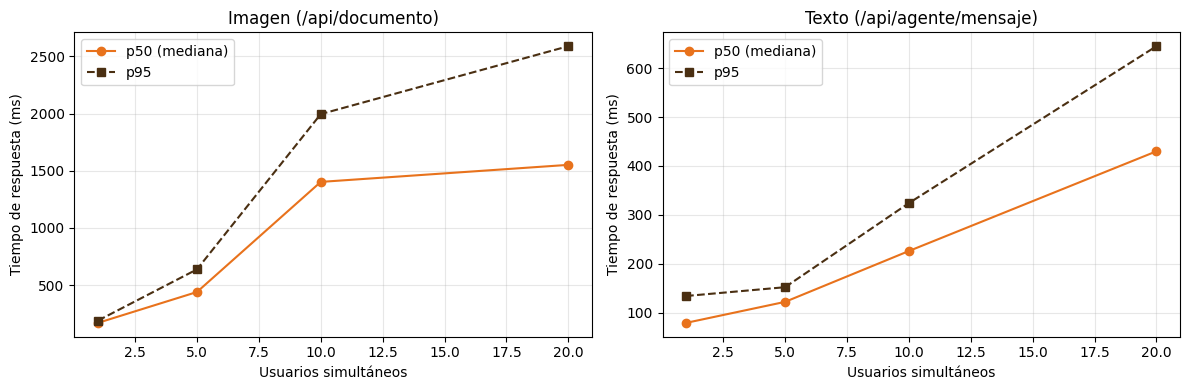

In [38]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (servicio, datos) in zip(ejes, carga.groupby('servicio')):
    ax.plot(datos['usuarios_simultaneos'], datos['latencia_p50_ms'], 'o-', color='#E8721C', label='p50 (mediana)')
    ax.plot(datos['usuarios_simultaneos'], datos['latencia_p95_ms'], 's--', color='#4A2F12', label='p95')
    ax.set_title(servicio); ax.set_xlabel('Usuarios simultáneos'); ax.set_ylabel('Tiempo de respuesta (ms)')
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## ⛔ Cierre (ejecútala solo al final)

**No uses "Ejecutar todo".** Esta celda apaga la API y el túnel: después de ejecutarla, la URL pública deja de funcionar (Cloudflare muestra *Error 1033*).

In [39]:
# Al terminar, cierra el túnel y la API
tunel.terminate(); api.terminate()